# ЛАБОРАТОРНА РОБОТА 6
## **Prac 06.2**

In [65]:
import cv2
import dlib
import os
import matplotlib.pyplot as plt

In [66]:
video_path = "cars.gif"

### 1. Функція відстеження об'єкта за допомогою трекера

In [67]:
def track_object(video_path, tracker_type, num_frames=15):
    
    video = cv2.VideoCapture(video_path)
    ret, frame = video.read()

    bbox = cv2.selectROI("Select object", frame, False)
    cv2.destroyWindow("Select object")

    if tracker_type == "KCF":
        tracker = cv2.legacy.TrackerKCF_create()
    elif tracker_type == "CSRT":
        tracker = cv2.legacy.TrackerCSRT_create()

    tracker.init(frame, bbox)

    results = []
    result = frame.copy()

    x, y, w, h = [int(v) for v in bbox]
    cv2.rectangle(result, (x, y), (x + w, y + h), (0, 255, 0), 2)
    results.append(result)

    for i in range(num_frames - 1):

        ret, frame = video.read()

        if not ret:
            break

        success, bbox = tracker.update(frame)
        result = frame.copy()

        if success:
            
            x, y, w, h = [int(v) for v in bbox]
            cv2.rectangle(result, (x, y), (x + w, y + h), (0, 255, 0), 2)
            
        else:
            
            cv2.putText(result, "Tracking failure", (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)

        results.append(result)

    video.release()

    return results

### 2. Застосування трекеру KCF

In [68]:
kcf_results = track_object( video_path, "KCF", num_frames=15)

os.makedirs("kcf_frames", exist_ok=True)

for i, frame in enumerate(kcf_results):
    cv2.imwrite(f"kcf_frames/frame_{i + 1}.jpg", frame)

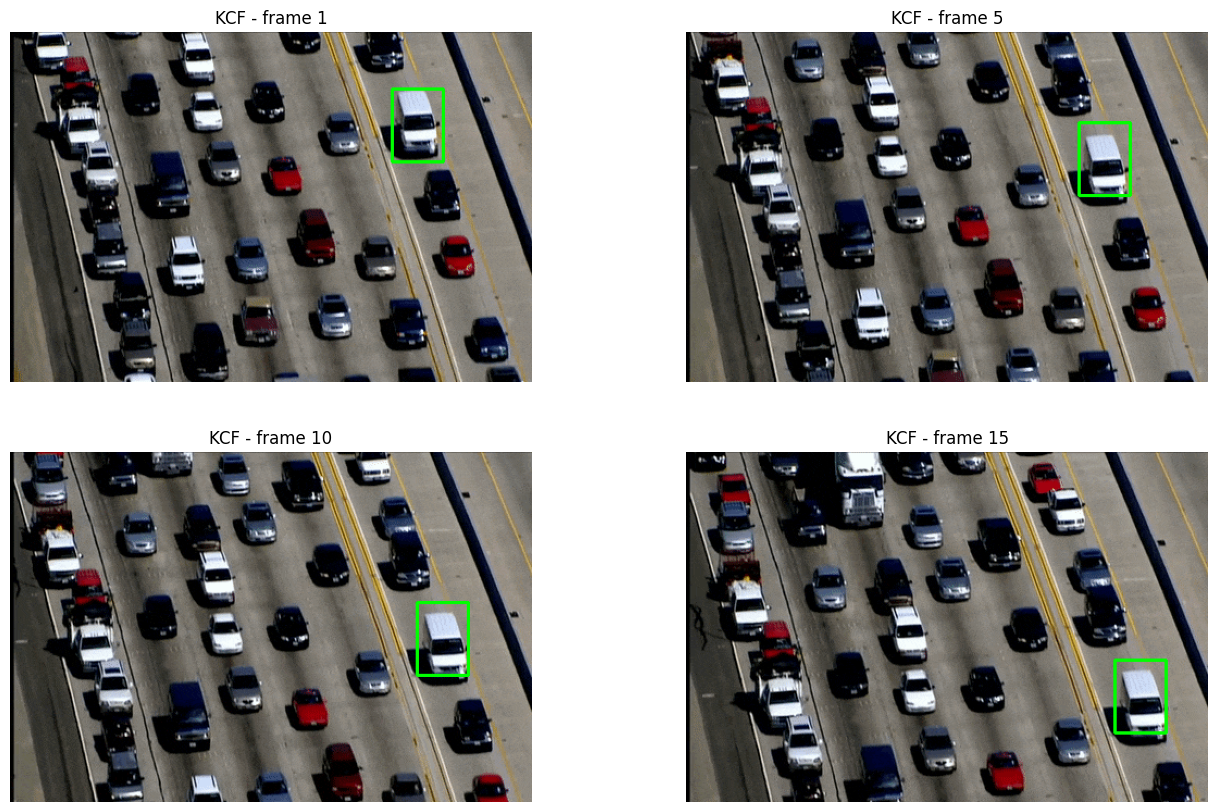

In [69]:
indices = [0, 4, 9, 14]

plt.figure(figsize=(16, 10))

for i, idx in enumerate(indices):
    
    plt.subplot(2, 2, i + 1)
    plt.imshow(cv2.cvtColor(kcf_results[idx], cv2.COLOR_BGR2RGB))
    plt.title(f"KCF - frame {idx + 1}")
    plt.axis("off")

plt.show()

### 3. Застосування трекеру CSRT

In [72]:
csrt_results = track_object( video_path, "CSRT", num_frames=15)

os.makedirs("csrt_frames", exist_ok=True)

for i, frame in enumerate(csrt_results):
    cv2.imwrite(f"csrt_frames/frame_{i + 1}.jpg", frame)

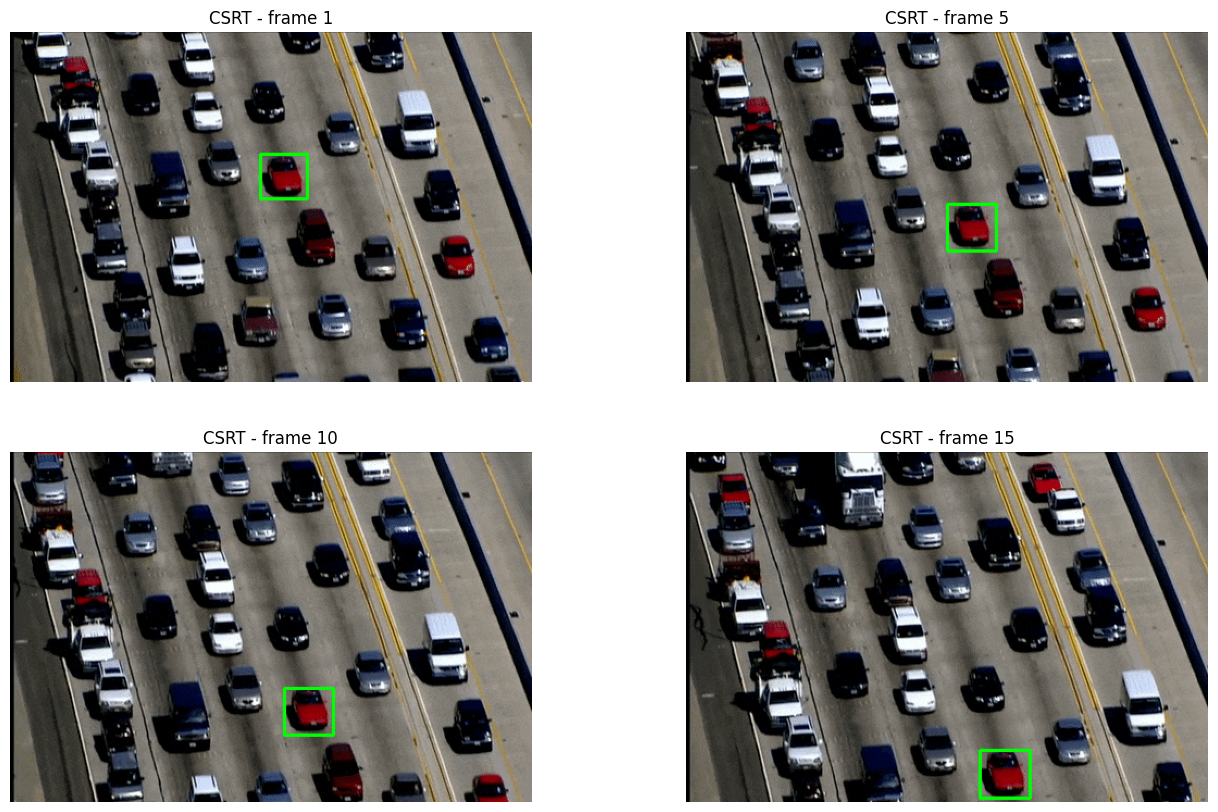

In [73]:
plt.figure(figsize=(16, 10))

for i, idx in enumerate(indices):
    
    plt.subplot(2, 2, i + 1)
    plt.imshow(cv2.cvtColor(csrt_results[idx], cv2.COLOR_BGR2RGB))
    plt.title(f"CSRT - frame {idx + 1}")
    plt.axis("off")

plt.show()